Importation des librairies

In [2]:
import pandas as pd #obligatoire
import numpy as np #obligatoire
from math import sqrt
import matplotlib.pyplot as plt #obligatoire
from sklearn.model_selection import train_test_split #obligatoire/séparation données
from sklearn.linear_model import LinearRegression #obligatoire/définition du modèle
from sklearn.metrics import mean_squared_error, r2_score
from sklearn import preprocessing #obligatoire/normaliser les données
import seaborn as sns

Lecture fichier

In [4]:
data = pd.read_csv ('C://Users//farge//Desktop//IA//TD//Sarron//TD 1//winequality-red.csv', delimiter=";") 
#ouvrir le document avant pour voir nature du delimiter
data

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


Analyse dataset

In [5]:
data.info() 
#déterminer nombre d'entrées (1598) et colonnes (12)

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
data.isnull().sum() 
#révéler valeurs manquantes/.sum pour renvoyer la somme de valeurs manquantes par colonne

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [7]:
data.describe() #afficher moyenne, ecart-type, min, quantil, max
#comparer moyennes entre colonnes (varie trop = indice de normalisation nécessaire)
#std/mean*100 doit être entre 5 et 10% en général sinon peu précis
#max et min aident à trouver outliners mais avec analyses en plus (boîte à moustache) là on peut juste suspecter

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [8]:
data.rename(columns = {"fixed acidity":"fixed_acidity","volatile acidity" : "volatile_acidity", "citric acid":"citric_acid", "residual sugar":"residual_sugar","free sulfur dioxide":"free_sulfur_dioxide","total sulfur dioxide":"total_sulfur_dioxide"}, inplace = True)
#besoin de renommer colonnes car contiennent espaces ce qui pose problème pour modèle
#inplace modifie directement dans tableau et n'en recrée pas un nouveau

<Axes: >

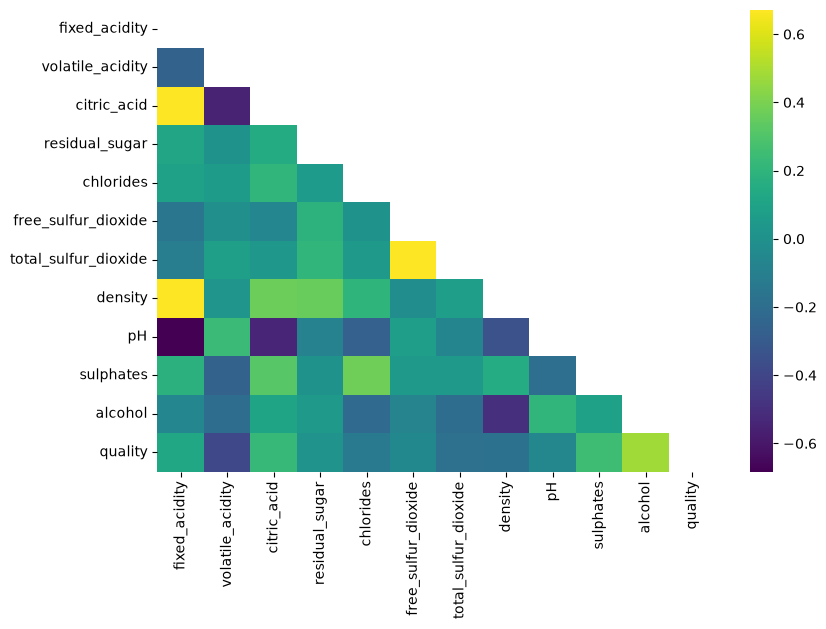

In [9]:
corr = data.corr()
#matrice de corrélation sert à lier colonnes entre elles en disant si liées ou non
plt.figure(figsize=(9,6))
sns.heatmap(corr, fmt = '.2g', cmap = 'viridis', mask = np.triu(corr))
#fmt sert à choisir typo
#mask sert à masquer partie non intéressante au delà de diagonale
#0 pas de corrélation
#positif corrélation positive
#négatif corrélation négative
#pour la qualité, les corrélations identifiées sont l'alcool et l'acidité volatile (positives)

In [10]:
y = data[['quality']].copy()
#création de notre variable à étudier
data = data.drop(['quality'], axis=1)
#axis=1 sert à enlever toute colonne et pas que cellule

Normaliser les données

In [12]:
def normalization(dataToNormalize) :
    columns = dataToNormalize.columns #indiquer au programme que la première ligne sont des colonnes donc à ne pas normaliser
    for col in columns :
        x = dataToNormalize[[col]].values.astype(float) #float pour avoir le même type de données partout (décimal)
        standard_normalization = preprocessing.StandardScaler() #indiquer quel type de normalisation appliquer
        res = standard_normalization.fit_transform(x) #normaliser données
        dataToNormalize[col] = res #appliquer données normalisées à colonnes
normalization(data)
data
#devrait être entre -1 et 1 si ce n'est pas le cas c'est qu'il y a des valeurs aberrantes, ici on va les laisser

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
0,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246
1,-0.298547,1.967442,-1.391472,0.043416,0.223875,0.872638,0.624363,0.028261,-0.719933,0.128950,-0.584777
2,-0.298547,1.297065,-1.186070,-0.169427,0.096353,-0.083669,0.229047,0.134264,-0.331177,-0.048089,-0.584777
3,1.654856,-1.384443,1.484154,-0.453218,-0.264960,0.107592,0.411500,0.664277,-0.979104,-0.461180,-0.584777
4,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246
...,...,...,...,...,...,...,...,...,...,...,...
1594,-1.217796,0.403229,-0.980669,-0.382271,0.053845,1.542054,-0.075043,-0.978765,0.899886,-0.461180,0.072294
1595,-1.390155,0.123905,-0.877968,-0.240375,-0.541259,2.211469,0.137820,-0.862162,1.353436,0.601055,0.729364
1596,-1.160343,-0.099554,-0.723916,-0.169427,-0.243707,1.255161,-0.196679,-0.533554,0.705508,0.542042,0.541630
1597,-1.390155,0.654620,-0.775267,-0.382271,-0.264960,1.542054,-0.075043,-0.676657,1.677400,0.305990,-0.209308


Séparation des données

In [13]:
x_train, x_test, y_train, y_test = train_test_split(data, y, test_size=0.20, random_state=42)
#random_state pour s'assurer qu'on obtienne tous pareil
#data correspond aux x
#size 20% et 80%

Définition du modèle

In [14]:
regression_alg = LinearRegression() #choix du modèle
regression_alg.fit(x_train, y_train) #appliquer modèle à nos données

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 11)","[[ 0.04,-0.18,-0.03,...,-0.06, 0.14, 0.3 ]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['fixed_acidity','volatile_acidity','citric_acid',...,'pH','sulphates', 'alcohol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5.63]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


Evaluer modèle (entraînement)

In [15]:
train_predictions = regression_alg.predict(x_train)
print(f"RMSE = {round(sqrt(mean_squared_error(y_train, train_predictions)),2)}")
print(f"R2_score = {round(r2_score(y_train, train_predictions) ,2)}")
#comparer théorie et valeur

RMSE = 0.65
R2_score = 0.35


Test modèle

In [16]:
test_predictions = regression_alg.predict(x_test)
print(f"RMSE = {round(sqrt(mean_squared_error(y_test, test_predictions)),2)}")
print(f"R2_score = {round(r2_score(y_test, test_predictions) ,2)}")

RMSE = 0.62
R2_score = 0.4


Coefficients d'équation

In [18]:
regression_alg.coef_ 
#chaque valeur représente un téta

array([[ 0.04018122, -0.1792372 , -0.0274236 ,  0.00925231, -0.08499703,
         0.05884439, -0.11984784, -0.0195308 , -0.06076105,  0.14253987,
         0.30030663]])

In [19]:
regression_alg.intercept_ 
#ordonnée à l'origine

array([5.62942467])